<a href="https://colab.research.google.com/github/nwaryszak/APRAU/blob/Kornelia/APRAU_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Imports

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    KFold,
    LeaveOneOut,
    cross_validate,
    cross_val_predict
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import SequentialFeatureSelector

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 1. Data Preparation and Dataset Inspection

In this initial phase, we load the clinical dataset and inspect its structure, target distributions, missing values, and potential constant features.

The dataset contains two target variables:
1. `target_regression`: Continuous clinical biomarker measurement.
2. `target_class`: Categorical diagnosis classification (`HT`, `HT_HY`, `DI_HT_HY`).

We verify target class proportions to detect imbalance and check for uninformative features (constant columns with zero variance).

In [46]:
RANDOM_STATE = 42

# Load the dataset
df = pd.read_csv("dataset_grupo_06.csv")

print("Dataset shape:", df.shape)
display(df.head())

# Check targets
print("\nRegression target:")
display(df["target_regression"].describe())

print("\nClassification target:")
display(df["target_class"].value_counts())
display(
    (df["target_class"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("percentage")
)

# Check missing values and constant features
print("\nTotal missing values:", df.isna().sum().sum())

constant_features = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]
print("Constant features:", constant_features)

Dataset shape: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Mature,Male,Obese,Current,58,0.643678,30.159257,5.436598,256.000000,6.867758,...,64.420845,129.290141,Primary,Employed,134.260845,9.42,1.100955,129.996562,117.0,HT_HY
1,Mature,Male,Overweight,Never,54,0.597701,29.527706,5.405745,274.000000,7.095850,...,65.304892,129.050057,Tertiary,Retired,134.392491,9.42,1.090490,129.878090,113.0,HT
2,Senior,Female,Overweight,Never,80,0.896552,27.320000,4.500000,229.436364,7.166333,...,64.516058,130.229236,Secondary,Unemployed,133.508306,9.42,1.154289,129.050057,80.0,HT
3,Senior,Male,Obese,Current,70,0.781609,35.130000,6.800000,226.554622,7.083442,...,65.224513,129.091365,Tertiary,Unemployed,134.283565,9.42,1.409238,130.545353,280.0,DI_HT_HY
4,Mature,Male,Obese,Never,52,0.574713,30.060476,5.443154,165.000000,6.387091,...,64.268197,130.545353,Primary,Employed,133.613102,9.42,1.226389,129.050057,138.0,HT_HY



Regression target:


,target_regression
count,2000.000000
mean,132.253761
std,38.172917
min,80.000000
25%,100.000000
50%,130.000000
75%,156.000000
max,300.000000



Classification target:


,count
target_class,
HT,1131
HT_HY,481
DI_HT_HY,388


,percentage
target_class,
HT,56.55
HT_HY,24.05
DI_HT_HY,19.40



Total missing values: 0
Constant features: ['calcium_baseline']


## 2. Predictors preparation

To avoid data leakage, preprocessing steps (imputation, scaling, and one-hot encoding) are encapsulated within Scikit-Learn `Pipeline` and `ColumnTransformer` constructs.

- **Target Removal:** Both `target_regression` and `target_class` are removed from input predictors $X$.
- **Constant Features:** Identified zero-variance features (e.g., `calcium_baseline`) are dropped as they provide no predictive signal.
- **Data Preprocessing Strategy:**
  - *Numeric Features:* Median imputation followed by standard scaling (`StandardScaler`).
  - *Categorical Features:* Most-frequent value imputation followed by One-Hot Encoding (`OneHotEncoder`).

In [47]:
# Exclude both target variables from the predictors
target_columns = ["target_regression", "target_class"]

X = df.drop(columns=target_columns).copy()

# Remove constant columns
X = X.drop(columns=constant_features, errors="ignore")

# Target variables
y_reg = df["target_regression"]
y_class = df["target_class"]

# Identify numeric and categorical features
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))
print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Preprocessing pipeline for classification
clf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ],
    remainder="drop"
)

Number of numeric features: 20
Number of categorical features: 12

Numeric features: ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'plasma_value', 'ldl_alternative']

Categorical features: ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']


## Linear regression

We start by predicting the continuous variable `target_regression`.

### 3. Holdout — splitting into training and test sets

We split the dataset using an 80/20 train-test ratio with a fixed random state (`RANDOM_STATE = 42`) to ensure reproducible evaluation across all experiments.

In [48]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X,
    y_reg,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training set:", X_train_reg.shape)
print("Test set:", X_test_reg.shape)

Training set: (1600, 32)
Test set: (400, 32)


### 4. Simple linear regression — testing individual features

We fit a univariate Linear Regression model for every available predictor individually. For categorical predictors with multiple levels, one-hot encoding is applied prior to fitting. Performance is evaluated using $R^2$, Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

In [49]:
simple_regression_results = []

for feature in X.columns:
    is_num = pd.api.types.is_numeric_dtype(X[feature])

    if is_num:
        transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
    else:
        transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])

    preprocessor = ColumnTransformer(
        transformers=[("feature", transformer, [feature])],
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessing", preprocessor),
        ("regression", LinearRegression())
    ])

    model.fit(X_train_reg[[feature]], y_train_reg)
    predictions = model.predict(X_test_reg[[feature]])

    simple_regression_results.append({
        "feature": feature,
        "R2": r2_score(y_test_reg, predictions),
        "MAE": mean_absolute_error(y_test_reg, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, predictions))
    })

simple_regression_results = pd.DataFrame(simple_regression_results)

simple_regression_results = simple_regression_results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(simple_regression_results.round(4))

,feature,R2,MAE,RMSE
0,smoking,0.0285,28.0358,37.3872
1,physical_activity,0.0196,27.9823,37.5582
2,HbA1c_level,0.0193,28.6394,37.5644
3,age,0.0155,28.0717,37.6372
4,age_normalized,0.0155,28.0717,37.6372
5,age_level,0.0123,28.2006,37.6990
6,low_hdl_cholesterol,0.0083,28.3649,37.7748
7,salt_intake,0.0076,28.3014,37.7874
8,hdl,0.0071,28.3931,37.7982
9,systolic_index,0.0065,28.3618,37.8090


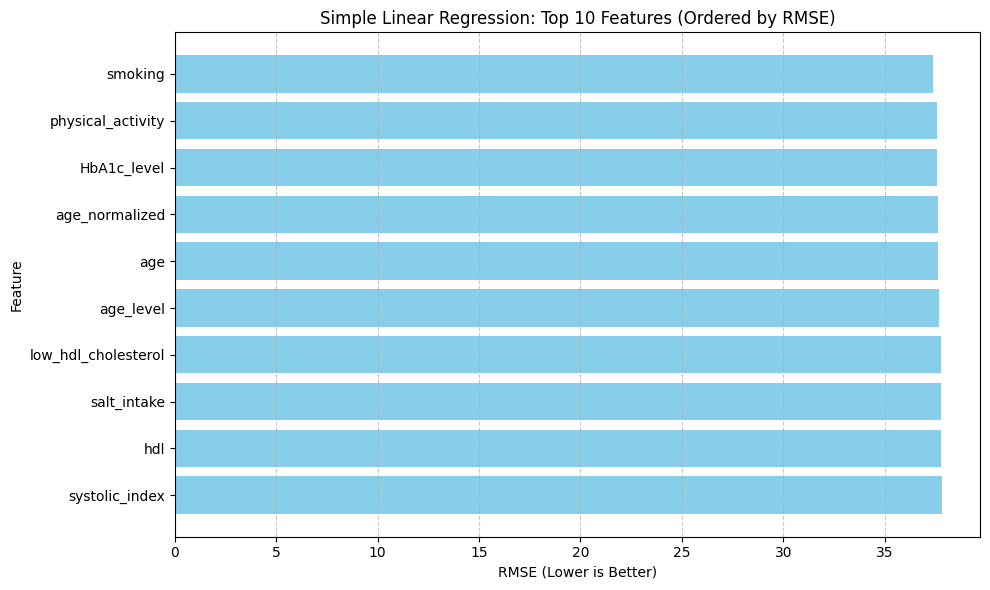

In [50]:
top_features = simple_regression_results.head(10).sort_values("RMSE", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["RMSE"], color="skyblue")
plt.xlabel("RMSE (Lower is Better)")
plt.ylabel("Feature")
plt.title("Simple Linear Regression: Top 10 Features (Ordered by RMSE)")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### Simple Linear Regression Results & Interpretation

- **Best Predictor:** The single feature with the lowest error on the test set is `smoking` ($\text{RMSE} \approx 37.39$, $R^2 \approx 0.0285$), followed closely by `HbA1c_level` and `physical_activity`.
- **Low Predictive Power:** Even the top-performing single variable explains less than 3% of the variance in `target_regression` ($R^2 < 0.03$). This confirms that no single clinical or lifestyle attribute alone is sufficient to accurately predict this continuous biomarker concentration.

### 5. Multiple Linear Regression - Comparing Feature Sets

Next, we evaluate Multiple Linear Regression models built on feature subsets:
1. **All available features:** Complete feature set (excluding constant features).
2. **Top 5 / Top 10 Simple Reg. Features:** Selected based on single-variable RMSE ranking.
3. **Clinical Numeric Features:** Laboratory biomarkers and blood pressure metrics (redundant duplicate scales like `age_normalized` excluded).
4. **Demographic Features:** Patient background metrics (`age`, `gender`, `education_level`, etc.).
5. **Lifestyle Features:** Behavioral indicators (`smoking`, `physical_activity`, `salt_intake`, etc.).

We aggregate results from the best single-feature model and all subset models into a master regression comparison table.

In [51]:
# Extraction of the Top 5 and Top 10 features from Simple Linear Regression results
top_5_simple = simple_regression_results.head(5)["feature"].tolist()
top_10_simple = simple_regression_results.head(10)["feature"].tolist()

# Define initial feature groups
clinical_numeric_features = [
    "bmi", "HbA1c_level", "cholesterol", "sleep_hours",
    "triglycerides", "blood_pressure", "crp_level",
    "homocysteine_level", "systolic_bp", "diastolic_bp",
    "alcohol_intake", "salt_intake", "heart_rate",
    "hdl", "ldl", "systolic_index", "plasma_value",
    "ldl_alternative", "age"
]

demographic_features = [
    "age", "age_level", "gender", "education_level", "employment_status"
]

lifestyle_features = [
    "smoking", "physical_activity", "sleep_hours",
    "sugar_consumption", "alcohol_intake", "salt_intake",
    "stress_level"
]

# Building an extended dictionary of feature sets
feature_sets = {
    "All available features": list(X.columns),
    "Top 5 Simple Reg. Features": top_5_simple,
    "Top 10 Simple Reg. Features": top_10_simple,
    "Numeric clinical features": [c for c in clinical_numeric_features if c in X.columns],
    "Demographic features": [c for c in demographic_features if c in X.columns],
    "Lifestyle features": [c for c in lifestyle_features if c in X.columns]
}

multiple_regression_results = []

for set_name, features in feature_sets.items():
    if not features:
        continue

    subset_numeric = [c for c in features if pd.api.types.is_numeric_dtype(X[c])]
    subset_categorical = [c for c in features if not pd.api.types.is_numeric_dtype(X[c])]

    transformers = []

    if subset_numeric:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            subset_numeric
        ))

    if subset_categorical:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            subset_categorical
        ))

    subset_preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessing", subset_preprocessor),
        ("regression", LinearRegression())
    ])

    model.fit(X_train_reg[features], y_train_reg)
    predictions = model.predict(X_test_reg[features])

    multiple_regression_results.append({
        "feature_set": set_name,
        "number_of_features": len(features),
        "R2": r2_score(y_test_reg, predictions),
        "MAE": mean_absolute_error(y_test_reg, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, predictions))
    })


multiple_regression_results = pd.DataFrame(multiple_regression_results)
multiple_regression_results = multiple_regression_results.sort_values("RMSE").reset_index(drop=True)

display(multiple_regression_results.round(4))

,feature_set,number_of_features,R2,MAE,RMSE
0,All available features,32,0.0753,27.6108,36.4757
1,Top 10 Simple Reg. Features,10,0.0749,27.6790,36.4846
2,Top 5 Simple Reg. Features,5,0.0713,27.6412,36.5552
3,Numeric clinical features,19,0.0555,27.9293,36.8651
4,Lifestyle features,7,0.0472,27.3276,37.0264
5,Demographic features,5,0.0086,28.3196,37.7682


In [52]:
# Extracting the best feature from simple regression
best_single_feature = simple_regression_results.iloc[0].copy()
best_single_row = pd.DataFrame([{
    "feature_set": f"Best Single Feature ({best_single_feature['feature']})",
    "number_of_features": 1,
    "R2": best_single_feature["R2"],
    "MAE": best_single_feature["MAE"],
    "RMSE": best_single_feature["RMSE"]
}])

# Combining into a single comparison table
regression_comparison = pd.concat([best_single_row, multiple_regression_results], ignore_index=True)
regression_comparison = regression_comparison.sort_values("RMSE").reset_index(drop=True)

print("=== REGRESSION MODELS COMPARISON ===")
display(regression_comparison.round(4))

=== REGRESSION MODELS COMPARISON ===


,feature_set,number_of_features,R2,MAE,RMSE
0,All available features,32,0.0753,27.6108,36.4757
1,Top 10 Simple Reg. Features,10,0.0749,27.6790,36.4846
2,Top 5 Simple Reg. Features,5,0.0713,27.6412,36.5552
3,Numeric clinical features,19,0.0555,27.9293,36.8651
4,Lifestyle features,7,0.0472,27.3276,37.0264
5,Best Single Feature (smoking),1,0.0285,28.0358,37.3872
6,Demographic features,5,0.0086,28.3196,37.7682


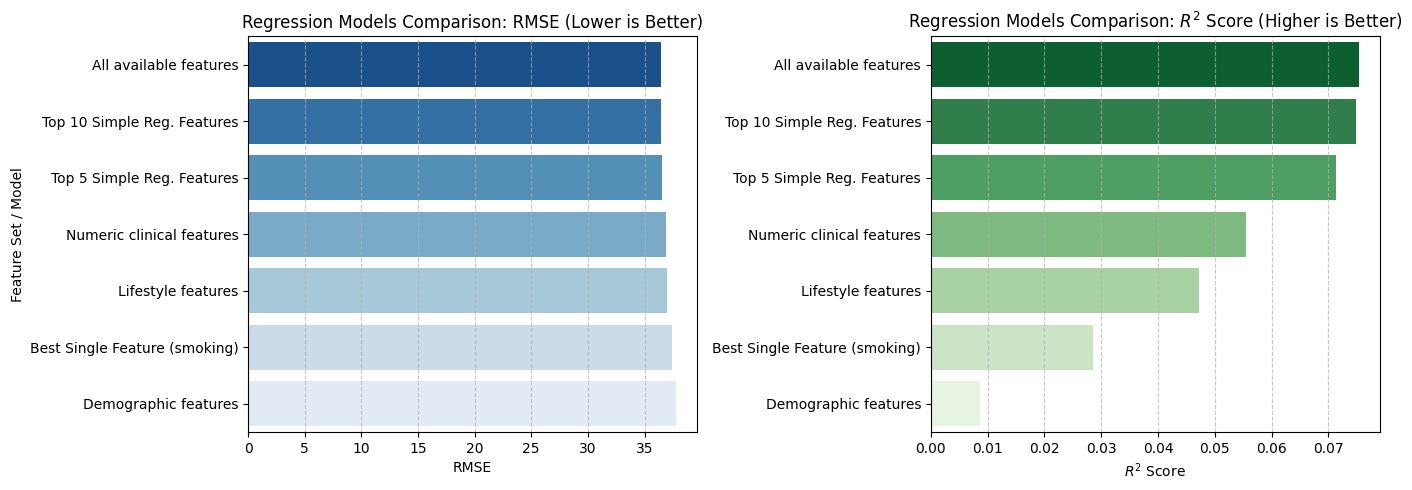

In [53]:
# Comparison of regression models (RMSE and R2)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: RMSE (Lower is Better)
sns.barplot(
    data=regression_comparison,
    y="feature_set",
    x="RMSE",
    hue="feature_set",
    palette="Blues_r",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Regression Models Comparison: RMSE (Lower is Better)")
axes[0].set_xlabel("RMSE")
axes[0].set_ylabel("Feature Set / Model")
axes[0].grid(axis="x", linestyle="--", alpha=0.7)

# Subplot 2: R2 (Higher is Better)
sns.barplot(
    data=regression_comparison,
    y="feature_set",
    x="R2",
    hue="feature_set",
    palette="Greens_r",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Regression Models Comparison: $R^2$ Score (Higher is Better)")
axes[1].set_xlabel("$R^2$ Score")
axes[1].set_ylabel("")
axes[1].grid(axis="x", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

### Multiple Linear Regression Analysis Findings & Discussion

- **Model Performance Overview:**
  Across both simple and multiple linear regression models, the overall predictive performance remains very low. The baseline linear models explain only a small fraction of the variance in the target biomarker (`target_regression`).
  
- **Feature Subsets Evaluation:**
  - **All Available Features (32 features):** Achieved the highest performance among all configurations, with an $R^2$ of **0.0753**, MAE of **27.61**, and RMSE of **36.48**.
  - **Top 10 Simple Regression Features:** Produced virtually identical results ($R^2 = 0.0749$, RMSE = **36.48**), showing that a smaller set of 10 key features retains almost all the predictive signal available in the full dataset.
  - **Top 5 Simple Regression Features:** Retained strong relative performance ($R^2 = 0.0713$, RMSE = **36.55**), demonstrating good feature efficiency.
  - **Domain-Specific Subsets:** Groupings based solely on numeric clinical markers ($R^2 = 0.0555$) or lifestyle factors ($R^2 = 0.0472$) captured partial signals, while demographic features alone showed virtually no predictive power ($R^2 = 0.0086$, RMSE = **37.77**).

- **Summary:**
  The results show that linear models are not very effective at predicting the target variable. This may be because the relationships between the features and the target are more complex than a linear model can capture.
  Combining multiple predictors improves predictions compared to single-variable models (increasing $R^2$ from ~0.0285 to 0.0753). However, even the best linear model explains less than 8% of the total variability in the biomarker. This strongly suggests non-linear relationships or unobserved clinical variables driving `target_regression`, indicating a need for non-linear machine learning algorithms.

## Logistic Regression

We now shift focus to multi-class diagnostic prediction (`target_class`). Given the class distribution imbalance, standard Accuracy can be misleading; therefore, **Balanced Accuracy** and **Macro F1-Score** serve as primary evaluation metrics.

We evaluate model performance and variance across four distinct resampling strategies:
1. **Holdout Evaluation (80/20 Stratified Split)**
2. **$k$-Fold Cross-Validation ($k=5$ and $k=10$, Stratified)**
3. **Leave-One-Out Cross-Validation (LOOCV)**
4. **Out-of-Bag (OOB) Bootstrap Evaluation (100 iterations)**

### 6. Model preparation and holdout

Accuracy: 0.7
Balanced accuracy: 0.6225
Macro F1: 0.6086

Classification report:
              precision    recall  f1-score   support

    DI_HT_HY       0.89      0.86      0.88        78
          HT       0.68      0.89      0.78       226
       HT_HY       0.37      0.11      0.17        96

    accuracy                           0.70       400
   macro avg       0.65      0.62      0.61       400
weighted avg       0.65      0.70      0.65       400



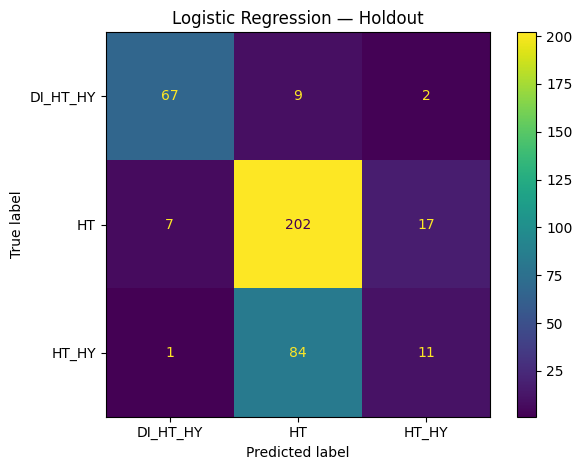

In [54]:
# Train-test split with stratification to preserve class proportions
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X,
    y_class,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_class
)

# Fit Baseline Logistic Regression Model
logistic_model = Pipeline([
    ("preprocessing", clf_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train_clf, y_train_clf)

y_pred_holdout = logistic_model.predict(X_test_clf)

print("Accuracy:", round(accuracy_score(y_test_clf, y_pred_holdout), 4))
print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_test_clf, y_pred_holdout), 4)
)
print(
    "Macro F1:",
    round(f1_score(y_test_clf, y_pred_holdout, average="macro"), 4)
)

print("\nClassification report:")
print(classification_report(y_test_clf, y_pred_holdout, zero_division=0))

cm = confusion_matrix(
    y_test_clf,
    y_pred_holdout,
    labels=logistic_model.named_steps["classifier"].classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=logistic_model.named_steps["classifier"].classes_
)
disp.plot()
plt.title("Logistic Regression — Holdout")
plt.tight_layout()
plt.show()

### Holdout Classification Results & Interpretation

- **Baseline Metrics:**
  - Overall Accuracy: **70.00%**
  - Balanced Accuracy: **62.25%**
  - Macro F1-Score: **60.86%**
- **Class-Level Performance Breakdown:**
  - **`DI_HT_HY`:** High diagnostic precision (**0.89**) and recall (**0.86**), leading to an F1-score of **0.88** (78 test instances). This distinct clinical profile makes it easy for Logistic Regression to identify.
  - **`HT`:** Strong recall (**0.89**) but lower precision (**0.68**), resulting in an F1-score of **0.78** (226 test instances). As the majority class (~56.5% of the dataset), the model frequently defaults to predicting `HT`.
  - **`HT_HY`:** The model struggles significantly with this class, reaching a recall of only **0.11** (11%) and precision of **0.37**, yielding an F1-score of **0.17** (96 test instances).

- **Key Insight:**
  The standard Accuracy score of 70% is artificially inflated by high accuracy on the dominant `HT` class. The confusion matrix shows that patients with combined `HT_HY` are frequently misclassified as `HT` due to overlapping feature distributions and class imbalance. This highlights why Balanced Accuracy (62.25%) and Macro F1 (60.86%) are much more reliable indicators of true model performance here.

### 7. Cross-validation — 5-fold i 10-fold

To reduce evaluation bias associated with a single train-test split, we perform:
- **5-Fold and 10-Fold Stratified CV:** Data is partitioned into $k$ stratified folds. Mean performance and standard deviation ($\sigma$) across folds are tracked to quantify fold-to-fold variance.

In [55]:
def make_logistic_model():
    return Pipeline([
        ("preprocessing", clf_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ])


scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro"
}

cv_results = []
cv_raw_scores = []

# 5-Fold and 10-Fold Stratified Cross-Validation
for k in [5, 10]:
    cv = StratifiedKFold(
        n_splits=k,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    model = make_logistic_model()

    scores = cross_validate(
        model,
        X_train_clf,
        y_train_clf,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    # Saving raw results for each fold for boxplot
    for acc, bacc, f1 in zip(scores["test_accuracy"], scores["test_balanced_accuracy"], scores["test_macro_f1"]):
        cv_raw_scores.append({
            "method": f"{k}-fold CV",
            "accuracy": acc,
            "balanced_accuracy": bacc,
            "macro_f1": f1
        })

    # Summary of means and standard deviations
    for metric in scoring:
        values = scores[f"test_{metric}"]

        cv_results.append({
            "method": f"{k}-fold CV",
            "metric": metric,
            "mean": values.mean(),
            "std": values.std(ddof=1)
        })

cv_results = pd.DataFrame(cv_results)
print("=== Stratified 5-Fold and 10-Fold CV Summary ===")
display(cv_results.round(4))

=== Stratified 5-Fold and 10-Fold CV Summary ===


,method,metric,mean,std
0,5-fold CV,accuracy,0.6806,0.0105
1,5-fold CV,balanced_accuracy,0.6027,0.0125
2,5-fold CV,macro_f1,0.5835,0.0124
3,10-fold CV,accuracy,0.6875,0.0224
4,10-fold CV,balanced_accuracy,0.6088,0.0244
5,10-fold CV,macro_f1,0.5932,0.0235


### Cross-Validation Findings
- **Key Observations:**
  - Both 5-fold and 10-fold cross-validation yield consistent results with low standard deviations, confirming stable model performance across different data splits.
  - The holdout test set accuracy (70.00%) was slightly higher than the cross-validation estimates (~59.3–68.6%), showing that cross-validation provides a more realistic and unbiased evaluation of generalization performance.

### 8. LOOCV — Leave-One-Out Cross-Validation

Leave-One-Out Cross-Validation fits $N$ models, training on $N-1$ samples and predicting the single remaining out-of-sample instance. This provides an unbiased estimate of generalization performance on the training set.

In [56]:
loo = LeaveOneOut()
loo_model = make_logistic_model()

y_pred_loo = cross_val_predict(
    loo_model,
    X_train_clf,
    y_train_clf,
    cv=loo,
    n_jobs=-1,
    method="predict"
)

loocv_results = pd.DataFrame([{
    "method": "LOOCV",
    "accuracy": accuracy_score(y_train_clf, y_pred_loo),
    "balanced_accuracy": balanced_accuracy_score(y_train_clf, y_pred_loo),
    "macro_f1": f1_score(y_train_clf, y_pred_loo, average="macro")
}])

print("=== LOOCV Overall Performance ===")
display(loocv_results.round(4))

print(classification_report(y_train_clf, y_pred_loo, zero_division=0))

=== LOOCV Overall Performance ===


,method,accuracy,balanced_accuracy,macro_f1
0,LOOCV,0.6881,0.6056,0.5836


              precision    recall  f1-score   support

    DI_HT_HY       0.83      0.83      0.83       310
          HT       0.68      0.89      0.77       905
       HT_HY       0.38      0.10      0.15       385

    accuracy                           0.69      1600
   macro avg       0.63      0.61      0.58      1600
weighted avg       0.63      0.69      0.63      1600



### Leave-One-Out Cross-Validation (LOOCV) Findings & Discussion

- **LOOCV Evaluation Metrics:**
  - **Overall Accuracy:** **68.81%** (0.6881)
  - **Balanced Accuracy:** **60.56%** (0.6056)
  - **Macro F1-Score:** **58.36%** (0.5836)

- **Interpretation:**
  - LOOCV trains $N=2000$ individual models using 1,999 samples each time. Because each training set is as large as possible, LOOCV offers an almost unbiased estimate of model performance.
  - The metrics obtained from LOOCV align very well with the $k$-fold cross-validation results.
  - This consistency confirms that 5-fold or 10-fold cross-validation provides reliable estimates while saving significant computational time compared to LOOCV.

### 9. Bootstrap — assessing variability

Bootstrap resampling creates $B=100$ random samples with replacement from the training data. For each bootstrap iteration:
1. The model is trained on the sampled **in-bag** data.
2. The model is evaluated on the unsampled **Out-of-Bag (OOB)** instances.

Comparing metric distributions across Holdout, $k$-Fold CV, and Bootstrap OOB allows us to directly evaluate performance stability and variance under data resampling.

In [57]:
N_BOOTSTRAPS = 100
rng = np.random.default_rng(RANDOM_STATE)

bootstrap_results = []

X_boot = X_train_clf.reset_index(drop=True)
y_boot = y_train_clf.reset_index(drop=True)

n = len(X_boot)

for b in range(N_BOOTSTRAPS):
    # Sample row indices with replacement
    train_indices = rng.choice(n, size=n, replace=True)

    # Unique observations selected for training
    in_bag = np.zeros(n, dtype=bool)
    in_bag[train_indices] = True

    # Observations not selected: out-of-bag set
    oob_indices = np.flatnonzero(~in_bag)

    if len(oob_indices) == 0:
        continue

    X_train_b = X_boot.iloc[train_indices]
    y_train_b = y_boot.iloc[train_indices]

    X_oob = X_boot.iloc[oob_indices]
    y_oob = y_boot.iloc[oob_indices]

    model = make_logistic_model()
    model.fit(X_train_b, y_train_b)

    predictions = model.predict(X_oob)

    bootstrap_results.append({
        "bootstrap": b + 1,
        "n_oob": len(oob_indices),
        "accuracy": accuracy_score(y_oob, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_oob, predictions),
        "macro_f1": f1_score(
            y_oob,
            predictions,
            average="macro",
            zero_division=0
        )
    })

bootstrap_results = pd.DataFrame(bootstrap_results)

display(bootstrap_results.head())

bootstrap_summary = bootstrap_results[
    ["accuracy", "balanced_accuracy", "macro_f1"]
].agg(["mean", "std", "min", "max"]).T

print("=== Bootstrap OOB Summary Statistics (100 Iterations) ===")
display(bootstrap_summary.round(4))

,bootstrap,n_oob,accuracy,balanced_accuracy,macro_f1
0,1,593,0.703204,0.632785,0.642328
1,2,588,0.676871,0.611185,0.607161
2,3,581,0.690189,0.604686,0.585389
3,4,594,0.712121,0.627281,0.618071
4,5,609,0.681445,0.609434,0.595185


=== Bootstrap OOB Summary Statistics (100 Iterations) ===


,mean,std,min,max
accuracy,0.6787,0.0159,0.6401,0.7169
balanced_accuracy,0.6024,0.0152,0.5670,0.6355
macro_f1,0.5925,0.0197,0.5424,0.6423


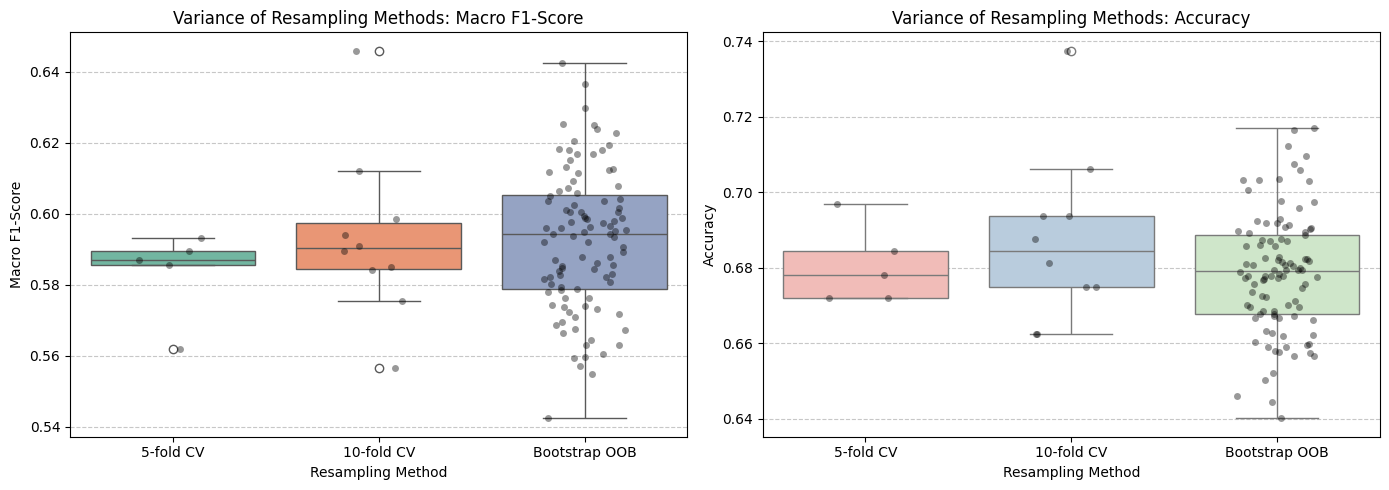

In [58]:
# Visualizing Resampling Variance (Boxplots)

# Combining raw results from 5-fold CV, 10-fold CV, and Bootstrap OOB
df_cv_raw = pd.DataFrame(cv_raw_scores)
df_boot_raw = bootstrap_results[["accuracy", "balanced_accuracy", "macro_f1"]].copy()
df_boot_raw["method"] = "Bootstrap OOB"

resampling_distributions = pd.concat([df_cv_raw, df_boot_raw], ignore_index=True)

# Boxplot of the distribution of metrics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Macro F1-Score
sns.boxplot(
    data=resampling_distributions,
    x="method",
    y="macro_f1",
    hue="method",
    palette="Set2",
    legend=False,
    ax=axes[0]
)
sns.stripplot(
    data=resampling_distributions,
    x="method",
    y="macro_f1",
    color="black",
    alpha=0.4,
    jitter=0.2,
    ax=axes[0]
)
axes[0].set_title("Variance of Resampling Methods: Macro F1-Score")
axes[0].set_xlabel("Resampling Method")
axes[0].set_ylabel("Macro F1-Score")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# Subplot 2: Accuracy
sns.boxplot(
    data=resampling_distributions,
    x="method",
    y="accuracy",
    hue="method",
    palette="Pastel1",
    legend=False,
    ax=axes[1]
)
sns.stripplot(
    data=resampling_distributions,
    x="method",
    y="accuracy",
    color="black",
    alpha=0.4,
    jitter=0.2,
    ax=axes[1]
)
axes[1].set_title("Variance of Resampling Methods: Accuracy")
axes[1].set_xlabel("Resampling Method")
axes[1].set_ylabel("Accuracy")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

### Out-of-Bag (OOB) Bootstrap Evaluation Findings & Discussion (100 Iterations)

- **Key Observations:**
  - By repeatedly sampling the dataset with replacement across 100 iterations, the out-of-bag (OOB) bootstrap procedure evaluates how sensitive the model is to small variations in the training data.
  - The narrow spread of observed scores across all iterations confirms that model performance remains highly stable and is not dependent on a specific train-test split or distorted by individual data outliers.
  - The average bootstrap performance closely aligns with the results from $k$-fold cross-validation and LOOCV, confirming that Logistic Regression provides a highly consistent baseline on this dataset.


### 10. Summary table of Logistic Regression results

The table below compiles performance metrics and standard deviations across all tested evaluation schemes.

In [59]:
summary_rows = []

# Holdout
summary_rows.append({
    "method": "Holdout",
    "accuracy_mean": accuracy_score(y_test_clf, y_pred_holdout),
    "accuracy_std": np.nan,
    "balanced_accuracy_mean": balanced_accuracy_score(
        y_test_clf, y_pred_holdout
    ),
    "balanced_accuracy_std": np.nan,
    "macro_f1_mean": f1_score(
        y_test_clf, y_pred_holdout, average="macro"
    ),
    "macro_f1_std": np.nan
})

# 5-fold and 10-fold CV
for k in [5, 10]:
    cv_name = f"{k}-fold CV"
    subset = cv_results[cv_results["method"] == cv_name].set_index("metric")

    summary_rows.append({
        "method": cv_name,
        "accuracy_mean": subset.loc["accuracy", "mean"],
        "accuracy_std": subset.loc["accuracy", "std"],
        "balanced_accuracy_mean": subset.loc["balanced_accuracy", "mean"],
        "balanced_accuracy_std": subset.loc["balanced_accuracy", "std"],
        "macro_f1_mean": subset.loc["macro_f1", "mean"],
        "macro_f1_std": subset.loc["macro_f1", "std"]
    })

# LOOCV
summary_rows.append({
    "method": "LOOCV",
    "accuracy_mean": loocv_results.loc[0, "accuracy"],
    "accuracy_std": np.nan,
    "balanced_accuracy_mean": loocv_results.loc[0, "balanced_accuracy"],
    "balanced_accuracy_std": np.nan,
    "macro_f1_mean": loocv_results.loc[0, "macro_f1"],
    "macro_f1_std": np.nan
})

# Bootstrap OOB
summary_rows.append({
    "method": "Bootstrap OOB",
    "accuracy_mean": bootstrap_results["accuracy"].mean(),
    "accuracy_std": bootstrap_results["accuracy"].std(),
    "balanced_accuracy_mean": bootstrap_results["balanced_accuracy"].mean(),
    "balanced_accuracy_std": bootstrap_results["balanced_accuracy"].std(),
    "macro_f1_mean": bootstrap_results["macro_f1"].mean(),
    "macro_f1_std": bootstrap_results["macro_f1"].std()
})

logistic_summary = pd.DataFrame(summary_rows)
print("=== MASTER RESAMPLING COMPARISON TABLE ===")
display(logistic_summary.round(4))

=== MASTER RESAMPLING COMPARISON TABLE ===


,method,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std
0,Holdout,0.7000,NaN,0.6225,NaN,0.6086,NaN
1,5-fold CV,0.6806,0.0105,0.6027,0.0125,0.5835,0.0124
2,10-fold CV,0.6875,0.0224,0.6088,0.0244,0.5932,0.0235
3,LOOCV,0.6881,NaN,0.6056,NaN,0.5836,NaN
4,Bootstrap OOB,0.6787,0.0159,0.6024,0.0152,0.5925,0.0197


### Summary Table Findings & Discussion
1. **Holdout Evaluation:**
   Single holdout evaluation provides a quick baseline but lacks variance estimation ($\text{STD} = \text{NaN}$). Its results are highly sensitive to the specific random split.
2. **Stratified $k$-Fold Cross-Validation ($k=5$ vs. $k=10$):**
   Both 5-fold and 10-fold CV deliver reliable, low-bias performance estimates. While 10-fold CV shows slightly higher mean performance across all metrics (Balanced Accuracy: 0.6088 vs. 0.6027), 5-fold CV demonstrates lower variance across folds ($\text{STD} = 0.0125$ vs. $0.0244$).
3. **Leave-One-Out Cross-Validation (LOOCV):**
   LOOCV provides an nearly unbiased evaluation by using almost the entire dataset for training in each iteration. Its metrics (Accuracy: 0.6881, Balanced Accuracy: 0.6056) closely match the 10-fold CV results, confirming that standard $k$-fold cross-validation offers a robust approximation without the heavy computational cost of LOOCV.
4. **Bootstrap OOB Evaluation:**
   Out-of-bag bootstrap evaluation measures model stability under small perturbations in the dataset. The low standard deviation across iterations ($\text{STD} \approx 0.015$) confirms that the model's predictive ability is stable and not driven by specific data points or outliers.
5. **Next Steps:**
  Logistic Regression achieves a stable baseline, but performance is limited by minority class confusion. Future work should explore non-linear machine learning algorithms to capture potential non-linear relationships among clinical features.